# Notebook 2 — Flower classification / ノートブック2：花の画像分類


**Time / 所要時間:** ~65–85 min (plus initial dataset download) / 約65〜85分（初回ダウンロード別）  
**Framework / フレームワーク:** PyTorch, as in the MNIST notebook / MNISTと同じPyTorch

### Learning goals / 学習目標
1. Move from grayscale to RGB images. / グレースケールからRGB画像への違いを理解する。
2. Load real images with different sizes. / サイズの異なる実画像を読み込む。
3. Train a small CNN on five flower categories. / 5種類の花をCNNで分類する。
4. Visualize augmentation, feature maps, errors, and confidence. / データ拡張・特徴マップ・誤分類・確信度を可視化する。

**Classes / 分類クラス:** daisy (デイジー), dandelion (タンポポ), roses (バラ), sunflowers (ヒマワリ), tulips (チューリップ).

**Important / 重要:** The dataset is downloaded online on first run (hundreds of MB). / 初回はデータのダウンロード（数百MB）が必要です。GPU runtime is recommended / GPU推奨。

**Instructor note / 教員向け:** Download and run once before class; performance on this small dataset will vary. This tutorial teaches the workflow, not state-of-the-art accuracy. / 事前に一度実行しておくことを推奨します。性能は環境や分割で変動します。

## 0. Environment / 実行環境
**EN:** Use the same PyTorch framework as MNIST to avoid learning two APIs. Set a seed and check whether CUDA is available. The notebook can run on CPU, but training will be slower.

**日本語:** MNISTと同じPyTorchを使うことで、異なるAPIを覚える負担を避けます。乱数シードを設定し、CUDAが使えるか確認します。CPUでも実行できますが、学習は遅くなります。

In [5]:
# Imports and reproducibility / ライブラリと再現性
import random, time, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
plt.rcParams["font.family"] = "Hiragino Sans"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device / 使用デバイス:', DEVICE)
# Google Colab: Runtime > Change runtime type > T4 GPU (optional)

PyTorch: 2.5.1 | Device / 使用デバイス: cpu


## 1. Download flowers / 花画像データのダウンロード
**EN:** We use the publicly available TensorFlow `flower_photos` sample dataset, but train with **PyTorch**. Images are stored in folders named after their labels, which `ImageFolder` can read. Download only from the specified HTTPS URL. The archive is checked for unsafe file paths before extraction.

**日本語:** 公開されているTensorFlowのサンプルデータ `flower_photos` を利用しますが、モデルの学習は **PyTorch** で行います。画像はクラスごとのフォルダに保存されており、`ImageFolder`で読み込めます。指定したHTTPSのURLから取得し、展開前に不正なパスを検査します。

Source / 配布元: https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz  
Reference / 参考: https://www.tensorflow.org/tutorials/images/classification?hl=ja

In [2]:
import tarfile, urllib.request
DATA_ROOT=Path('./flower_data')
FLOWER_DIR=DATA_ROOT/'flower_photos'
ARCHIVE=DATA_ROOT/'flower_photos.tgz'
DATA_ROOT.mkdir(parents=True,exist_ok=True)
if not FLOWER_DIR.exists():
    if not ARCHIVE.exists():
        print('Downloading flower photos / 花画像をダウンロードしています...')
        urllib.request.urlretrieve('https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',ARCHIVE)
    with tarfile.open(ARCHIVE,'r:gz') as tar:
        members=tar.getmembers()
        # Reject absolute paths, .., symlinks and unusual tar types.
        for member in members:
            parts=Path(member.name).parts
            if member.name.startswith('/') or '..' in parts or (not(member.isfile() or member.isdir())):
                raise ValueError(f'Unsafe archive entry: {member.name}')
        # Python tarfile extraction with compatibility across Colab runtimes.
        import shutil
        for member in members:
            dest=DATA_ROOT/member.name
            if member.isdir():
                dest.mkdir(parents=True,exist_ok=True)
            elif member.isfile():
                dest.parent.mkdir(parents=True,exist_ok=True)
                source=tar.extractfile(member)
                if source is not None:
                    with source,open(dest,'wb') as out:shutil.copyfileobj(source,out)
print('Data folder / データフォルダ:',FLOWER_DIR)
print('Exists / 存在確認:',FLOWER_DIR.exists())

Data folder / データフォルダ: flower_data/flower_photos
Exists / 存在確認: True


## 2. Understand RGB and split the data / RGBとデータ分割
**EN:** RGB images have three channels (red, green, blue), compared with one channel in MNIST. Real flower photos have different resolutions and varied backgrounds, poses, and lighting. We resize them to 96×96 for a short lesson. We make **stratified** 70%/15%/15% training/validation/test splits, preserving class proportions. The same image never appears in two splits. These are image-level splits; near-duplicate photographs may still exist across splits in the source dataset.

**日本語:** RGB画像は赤・緑・青の3チャネルを持ち、MNISTの1チャネルとは異なります。花の写真は元の解像度・背景・向き・照明がさまざまです。短時間の授業用に96×96へ変換します。今回はクラス割合を保つ**層化分割**で学習70％・検証15％・テスト15％に分けます。同じ画像が複数の集合に入ることはありません。ただし、元データに似た写真が含まれる可能性には注意してください。

**Terminology / 用語:** train = fit weights (重みの学習); validation = choose settings (設定選択); test = final held-out evaluation (最終評価).

In [3]:
from sklearn.model_selection import train_test_split
# ImageFolder reads labels from subdirectory names / サブフォルダ名からラベルを取得
base=datasets.ImageFolder(FLOWER_DIR)
class_names=base.classes
indices=np.arange(len(base));labels=np.array(base.targets)
train_idx,remaining_idx=train_test_split(indices,test_size=0.30,random_state=SEED,stratify=labels)
val_idx,test_idx=train_test_split(remaining_idx,test_size=0.50,random_state=SEED,stratify=labels[remaining_idx])
print('Classes / クラス:',class_names)
print('Counts / 枚数:',len(train_idx),len(val_idx),len(test_idx),'total',len(base))
print('Original image size / 元画像例:',base[0][0].size)
assert not(set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx))

Classes / クラス: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Counts / 枚数: 2569 550 551 total 3670
Original image size / 元画像例: (320, 263)


### See class distribution / クラスごとの枚数
**EN:** A class imbalance means some flower types appear more frequently. It can affect overall accuracy, so also inspect performance per class.

**日本語:** クラス不均衡とは花の種類ごとに枚数が異なる状態です。全体の正解率が偏る可能性があるため、クラス別の評価も確認します。

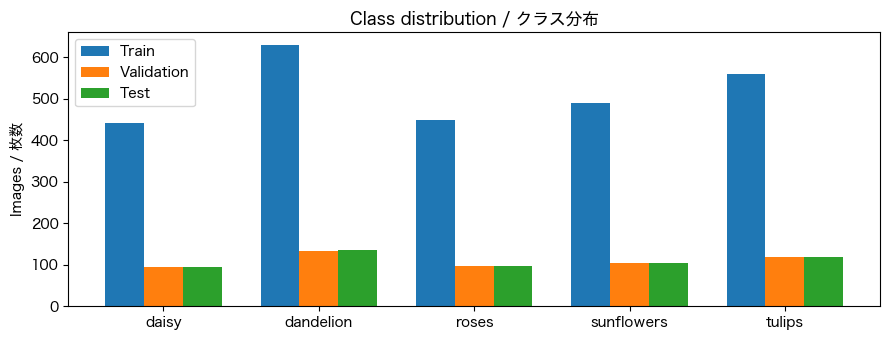

In [6]:
fig,ax=plt.subplots(figsize=(9,3.5))
xx=np.arange(len(class_names));width=.25
for offset,ids,name in [(-width,train_idx,'Train'),(0,val_idx,'Validation'),(width,test_idx,'Test')]:
    counts=np.bincount(labels[ids],minlength=len(class_names))
    ax.bar(xx+offset,counts,width,label=name)
ax.set_xticks(xx,class_names);ax.set_ylabel('Images / 枚数');ax.set_title('Class distribution / クラス分布');ax.legend()
plt.tight_layout();plt.show()

## 3. Preprocessing and augmentation / 前処理とデータ拡張
**EN:** A CNN needs tensors of consistent shape. `Resize(96,96)` makes images the same size, `ToTensor()` scales pixel values to [0,1], and `Normalize([0.5]×3,[0.5]×3)` maps values approximately to [−1,1]. On the training split **only**, random horizontal flips and small rotations create varied inputs to improve robustness. We do not augment validation/test images because we want stable, comparable evaluation.

**日本語:** CNNへまとめて入力するには画像サイズを統一します。`Resize(96,96)` でサイズを揃え、`ToTensor()` で値を0〜1にし、`Normalize` でおおむね−1〜1へ変換します。**学習データのみ**左右反転や小さな回転をランダムに加え、変化に強いモデルを目指します。検証・テスト画像にはランダムな拡張を行わず、評価の一貫性を保ちます。

**Caution / 注意:** Rotation and stretching may crop details; interpolation may distort aspect ratio. More advanced projects can preserve aspect ratio and use padding. / 回転による切り落としや縦横比の変化に注意してください。

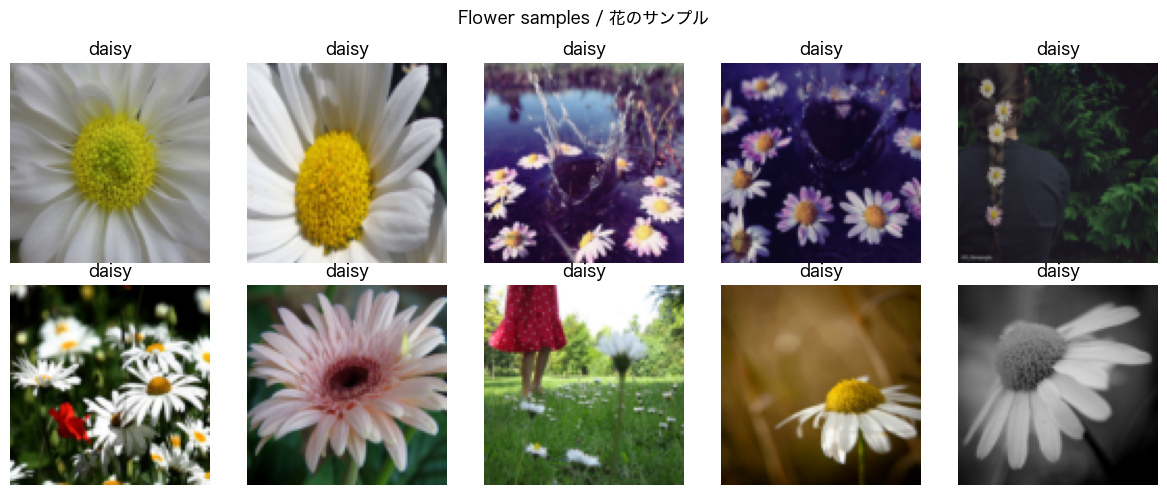

In [7]:
IMAGE_SIZE=96
mean=(0.5,0.5,0.5);std=(0.5,0.5,0.5)
train_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])
eval_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])
# Two ImageFolder objects allow distinct train/eval transforms.
train_all=datasets.ImageFolder(FLOWER_DIR,transform=train_transform)
eval_all=datasets.ImageFolder(FLOWER_DIR,transform=eval_transform)
train_data=Subset(train_all,train_idx.tolist())
val_data=Subset(eval_all,val_idx.tolist())
test_data=Subset(eval_all,test_idx.tolist())
BATCH_SIZE=64
train_loader=DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
val_loader=DataLoader(val_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(test_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

def undo_normalize(x):
    # x is CHW tensor; back to [0,1] / 正規化を元に戻す
    return (x.detach().cpu()*0.5+0.5).clamp(0,1).permute(1,2,0).numpy()

fig,axs=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axs.flat):
    img,y=eval_all[int(indices[i])]
    ax.imshow(undo_normalize(img));ax.set_title(class_names[y]);ax.axis('off')
plt.suptitle('Flower samples / 花のサンプル');plt.tight_layout();plt.show()

### Visualize augmentation / データ拡張の可視化
**EN:** These six images are random transformations of **one original image**. Notice how orientation changes while the flower label stays the same. Data augmentation does not physically create new independent photos.

**日本語:** 次の6枚は**同じ元画像1枚**にランダムな変換を施したものです。向きが変わっても花の種類は同じです。ただし、データ拡張によって完全に独立した新しい写真が増えるわけではありません。

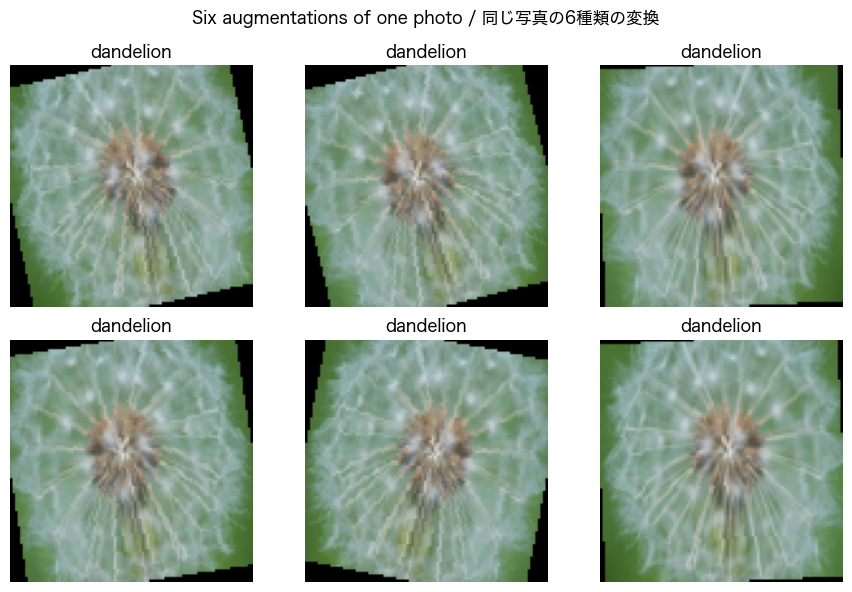

In [8]:
source_idx=int(train_idx[0]);raw_image,raw_label=base[source_idx]
fig,axs=plt.subplots(2,3,figsize=(9,6))
for ax in axs.flat:
    aug=train_transform(raw_image)
    ax.imshow(undo_normalize(aug));ax.axis('off');ax.set_title(class_names[raw_label])
plt.suptitle('Six augmentations of one photo / 同じ写真の6種類の変換');plt.tight_layout();plt.show()

## 4. Build a compact flower CNN / 花分類用の小さなCNN
**EN:** RGB input has 3 channels, so the first layer uses `Conv2d(3,16,...)`. Three convolution–ReLU–pool blocks learn progressively complex visual features. After pooling, `AdaptiveAvgPool2d(1)` summarizes each channel into one number, reducing classifier parameters. `Linear(64,5)` predicts five class logits.

**日本語:** RGB入力は3チャネルなので最初の層は `Conv2d(3,16,...)` です。畳み込み・ReLU・プーリングを3回繰り返し、段階的に特徴を抽出します。`AdaptiveAvgPool2d(1)` で各チャネルを1つの値に要約し、分類器のパラメータ数を抑えます。`Linear(64,5)` が5クラスのlogitを出力します。

**Size path / サイズ変化:** `3×96×96 → 16×48×48 → 32×24×24 → 64×12×12 → 64×1×1 → 64 → 5`.

**Important / 重要:** A from-scratch CNN may struggle more here than on MNIST because backgrounds, light, textures, and classes are more complex. / MNISTより複雑なので正解率は低い場合があります。

In [9]:
class FlowerCNN(nn.Module):
    def __init__(self,num_classes=5):
        super().__init__()
        self.conv1=nn.Conv2d(3,16,kernel_size=3,padding=1)
        self.relu1=nn.ReLU()
        self.pool1=nn.MaxPool2d(2)
        self.conv2=nn.Conv2d(16,32,kernel_size=3,padding=1)
        self.relu2=nn.ReLU()
        self.pool2=nn.MaxPool2d(2)
        self.conv3=nn.Conv2d(32,64,kernel_size=3,padding=1)
        self.relu3=nn.ReLU()
        self.pool3=nn.MaxPool2d(2)
        self.head=nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(),nn.Linear(64,num_classes))
    def forward(self,x):
        x=self.pool1(self.relu1(self.conv1(x)))
        x=self.pool2(self.relu2(self.conv2(x)))
        x=self.pool3(self.relu3(self.conv3(x)))
        return self.head(x)

model=FlowerCNN(num_classes=len(class_names)).to(DEVICE)
print(model)
print('Trainable parameters / 学習可能パラメータ数:',sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad(): print('Two-image output shape / 2枚に対する出力:',tuple(model(torch.randn(2,3,96,96,device=DEVICE)).shape))

FlowerCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (head): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(1, 1))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_features=5, bias=True)
  )
)
Trainable parameters / 学習可能パラメータ数: 23909
Two-image output shape / 2枚に対する出力: (2, 5)


## 5. Train and monitor / 学習と途中経過の可視化
**EN:** As with MNIST, we use cross-entropy loss and Adam. The training loop alternates optimization on training data and metric calculation on validation data. Validation loss selects the best epoch; the test set is not used here. A small CNN may require additional epochs for good accuracy. For class time, **3 epochs** is a useful quick demonstration; later increase to 8–12 to see the difference.

**日本語:** MNISTと同様に交差エントロピー損失とAdamを使います。学習データで重みを更新し、検証データで性能を確認します。最良のエポックは検証損失で選び、ここではテストデータを使いません。十分な性能には追加のエポックが必要な場合があります。授業中は**3エポック**で動作を確認し、授業後に8〜12エポックへ増やして比較できます。

**Why GPU? / GPUの利点:** Parallel convolution is much faster on a GPU, especially with color images. / GPUはカラー画像の畳み込みを高速に処理できます。

In [10]:
# Shared training helpers / 学習・評価用関数
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    sum_loss = correct = total = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        batch_size = images.size(0)
        sum_loss += loss.item() * batch_size
        correct += (logits.argmax(1) == labels).sum().item()
        total += batch_size
    return sum_loss/total, correct/total

def train_model(model, train_loader, val_loader, epochs=3, lr=0.001):
    criterion = nn.CrossEntropyLoss()  # logits + integer labels (no softmax here)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
    best_val = float('inf'); best_state = None
    for epoch in range(1, epochs+1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        with torch.no_grad():
            va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for k,v in zip(history, [tr_loss,tr_acc,va_loss,va_acc]): history[k].append(v)
        if va_loss < best_val:
            best_val = va_loss
            best_state = copy.deepcopy(model.state_dict())
        print(f'Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.3f}, acc {tr_acc:.1%} | '
              f'val loss {va_loss:.3f}, acc {va_acc:.1%} | {time.perf_counter()-t0:.1f}s')
    model.load_state_dict(best_state)  # choose checkpoint using validation only
    return history

def plot_history(history):
    fig, axes=plt.subplots(1,2,figsize=(11,3.6))
    axes[0].plot(history['train_loss'],marker='o',label='Train')
    axes[0].plot(history['val_loss'],marker='o',label='Validation')
    axes[0].set_title('Cross-entropy loss / 損失'); axes[0].set_ylabel('Loss')
    axes[1].plot(history['train_acc'],marker='o',label='Train')
    axes[1].plot(history['val_acc'],marker='o',label='Validation')
    axes[1].set_title('Accuracy / 正解率'); axes[1].set_ylabel('Accuracy')
    for ax in axes:
        ax.set_xlabel('Epoch index (starting at 0)');ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.show()

def get_predictions(model, loader):
    model.eval(); true=[]; pred=[]; prob=[]
    with torch.no_grad():
        for images,labels in loader:
            logits=model(images.to(DEVICE))
            probability=torch.softmax(logits,dim=1).cpu()
            true.extend(labels.tolist());pred.extend(probability.argmax(dim=1).tolist())
            prob.append(probability)
    return np.array(true),np.array(pred),torch.cat(prob).numpy()

Epoch  1/12 | train loss 1.196, acc 48.9% | val loss 1.188, acc 52.4% | 9.9s
Epoch  2/12 | train loss 1.170, acc 50.5% | val loss 1.151, acc 54.0% | 9.4s
Epoch  3/12 | train loss 1.136, acc 52.8% | val loss 1.163, acc 50.9% | 8.9s
Epoch  4/12 | train loss 1.105, acc 55.4% | val loss 1.115, acc 55.5% | 8.7s
Epoch  5/12 | train loss 1.089, acc 56.5% | val loss 1.095, acc 59.8% | 8.6s
Epoch  6/12 | train loss 1.081, acc 56.0% | val loss 1.090, acc 59.3% | 9.0s
Epoch  7/12 | train loss 1.058, acc 57.7% | val loss 1.074, acc 61.3% | 9.0s
Epoch  8/12 | train loss 1.042, acc 58.7% | val loss 1.143, acc 56.9% | 9.1s
Epoch  9/12 | train loss 1.021, acc 60.3% | val loss 1.126, acc 54.7% | 8.8s
Epoch 10/12 | train loss 1.027, acc 59.9% | val loss 1.082, acc 58.4% | 8.5s
Epoch 11/12 | train loss 1.017, acc 59.9% | val loss 1.072, acc 58.0% | 8.8s
Epoch 12/12 | train loss 0.989, acc 61.5% | val loss 1.068, acc 58.4% | 8.8s


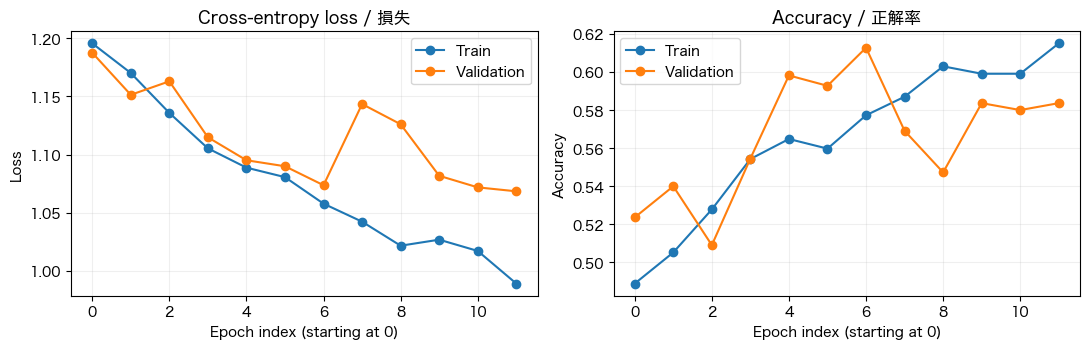

In [12]:
EPOCHS=3  # try 8–12 after class / 授業後に8〜12へ変更して比較
history=train_model(model,train_loader,val_loader,epochs=EPOCHS,lr=0.001)
plot_history(history)

## 6. Evaluate flower predictions / 花の予測を評価する
**EN:** The confusion matrix reveals which flower types the network confuses. Different classes have different frequencies, so inspect class-wise precision/recall and examples of mistakes rather than relying only on overall accuracy.

**日本語:** 混同行列を見ると、どの花同士を間違えやすいか分かります。クラスごとの枚数が異なるため、全体の正解率だけでなく、適合率・再現率・誤分類画像を確認します。

**Precision / 適合率:** Of examples predicted as a class, what fraction are correct? / そのクラスと予測した画像のうち正しい割合。  
**Recall / 再現率:** Of actual examples of a class, what fraction were found? / 実際にそのクラスである画像のうち正しく発見できた割合。

Test accuracy / テスト正解率: 61.34%


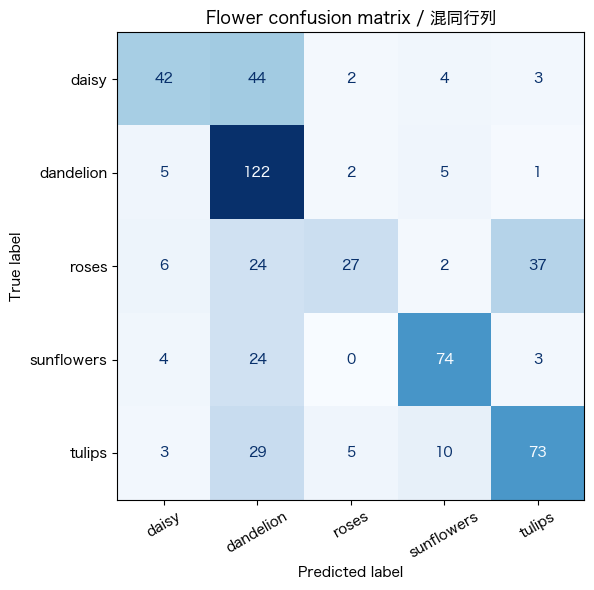

              precision    recall  f1-score   support

       daisy      0.700     0.442     0.542        95
   dandelion      0.502     0.904     0.646       135
       roses      0.750     0.281     0.409        96
  sunflowers      0.779     0.705     0.740       105
      tulips      0.624     0.608     0.616       120

    accuracy                          0.613       551
   macro avg      0.671     0.588     0.591       551
weighted avg      0.659     0.613     0.598       551



In [13]:
truth,pred,probs=get_predictions(model,test_loader)
print(f'Test accuracy / テスト正解率: {(truth==pred).mean():.2%}')
cm=confusion_matrix(truth,pred,labels=list(range(len(class_names))))
fig,ax=plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,cmap='Blues',colorbar=False,xticks_rotation=30)
ax.set_title('Flower confusion matrix / 混同行列');plt.tight_layout();plt.show()
print(classification_report(truth,pred,target_names=class_names,digits=3,zero_division=0))

### Look at incorrect predictions / 誤分類の画像を確認する
**EN:** A mistake can result from visually similar petals, background distractions, unusual viewpoints, occlusion, or too little training. The confidence score is softmax output and should not be treated as a perfectly calibrated probability.

**日本語:** 花びらが似ていること、背景の影響、珍しい向き、遮蔽、学習不足などが誤分類の原因になり得ます。確信度はsoftmax出力であり、正確に校正された確率とは限りません。

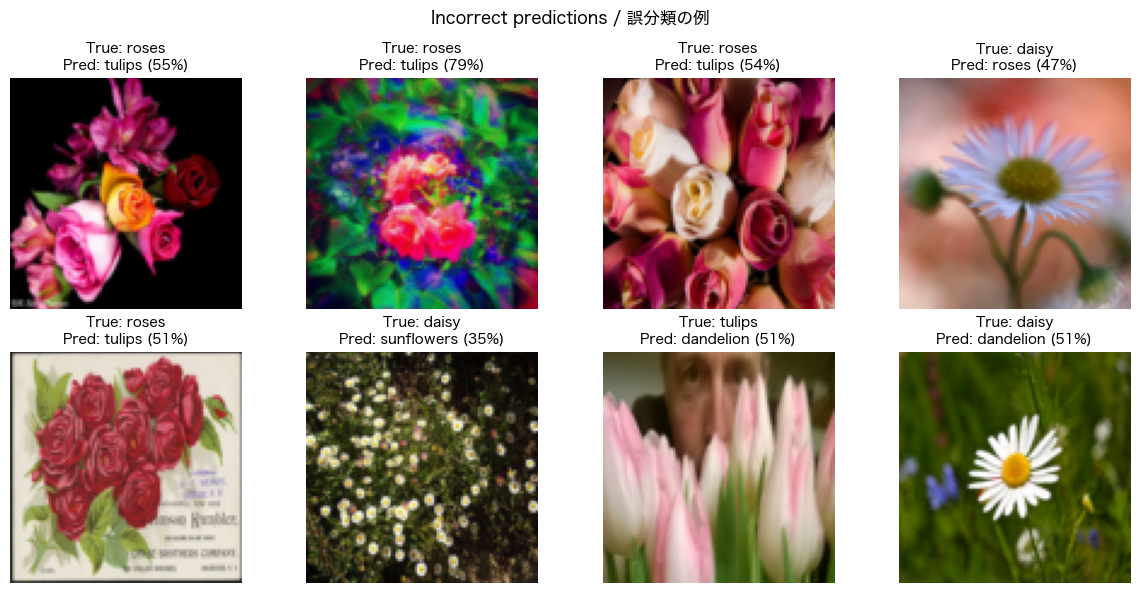

In [15]:
wrong=np.flatnonzero(truth!=pred)
fig,axs=plt.subplots(2,4,figsize=(12,6))
for ax,idx in zip(axs.flat,wrong[:8]):
    img,y=test_data[int(idx)]
    ax.imshow(undo_normalize(img));ax.axis('off')
    ax.set_title(f'True: {class_names[y]}\nPred: {class_names[pred[idx]]} ({probs[idx,pred[idx]]:.0%})',fontsize=10)
for ax in list(axs.flat)[min(len(wrong),8):]: ax.axis('off')
plt.suptitle('Incorrect predictions / 誤分類の例');plt.tight_layout();plt.show()

## 7. See intermediate feature maps / 中間特徴マップを可視化する
**EN:** A forward hook temporarily captures the output of a selected layer. Early maps often respond to color and edges; deeper maps are combinations of features. The visualization is **not** an explanation of exactly why a decision was made. Feature maps have different scales and are shown with independently adjusted colors.

**日本語:** forward hookを使って指定した層の出力を一時的に保存します。初期層は色やエッジなどに反応しやすく、深い層では特徴が組み合わされます。ただし、この表示だけで「なぜその予測をしたか」を厳密に説明できるわけではありません。チャネルごとに色のスケールが異なる点にも注意してください。

In [16]:
# Intermediate activations / 中間特徴マップ
# Hooks capture layer outputs during the forward pass.
# hook は順伝播中に指定した層の出力を保存します。
def show_feature_maps(model, image_tensor, layer, title, max_channels=12):
    cache = {}
    def save_output(module, inputs, output):
        cache['activation'] = output.detach().cpu()
    handle = layer.register_forward_hook(save_output)
    model.eval()
    with torch.no_grad(): model(image_tensor.unsqueeze(0).to(DEVICE))
    handle.remove()  # important: avoid accumulating hooks / hook の重複を防ぐ
    maps=cache['activation'][0]
    count=min(max_channels,maps.shape[0]); cols=4;rows=int(np.ceil(count/cols))
    fig,axs=plt.subplots(rows,cols,figsize=(cols*2.6,rows*2.5))
    for i,ax in enumerate(np.array(axs).reshape(-1)):
        if i<count:
            ax.imshow(maps[i],cmap='viridis'); ax.set_title(f'Channel {i}')
        ax.axis('off')
    fig.suptitle(f'{title} | shape={tuple(maps.shape)}',y=1.02)
    plt.tight_layout();plt.show()
    return maps

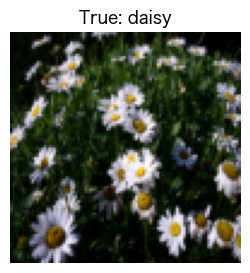

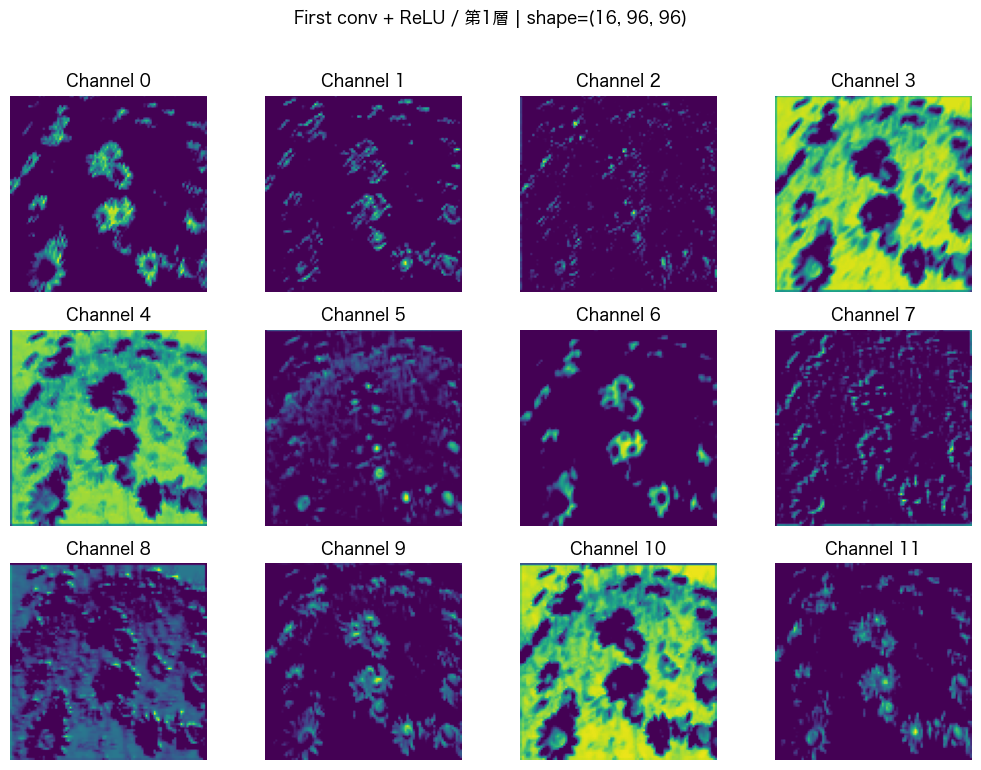

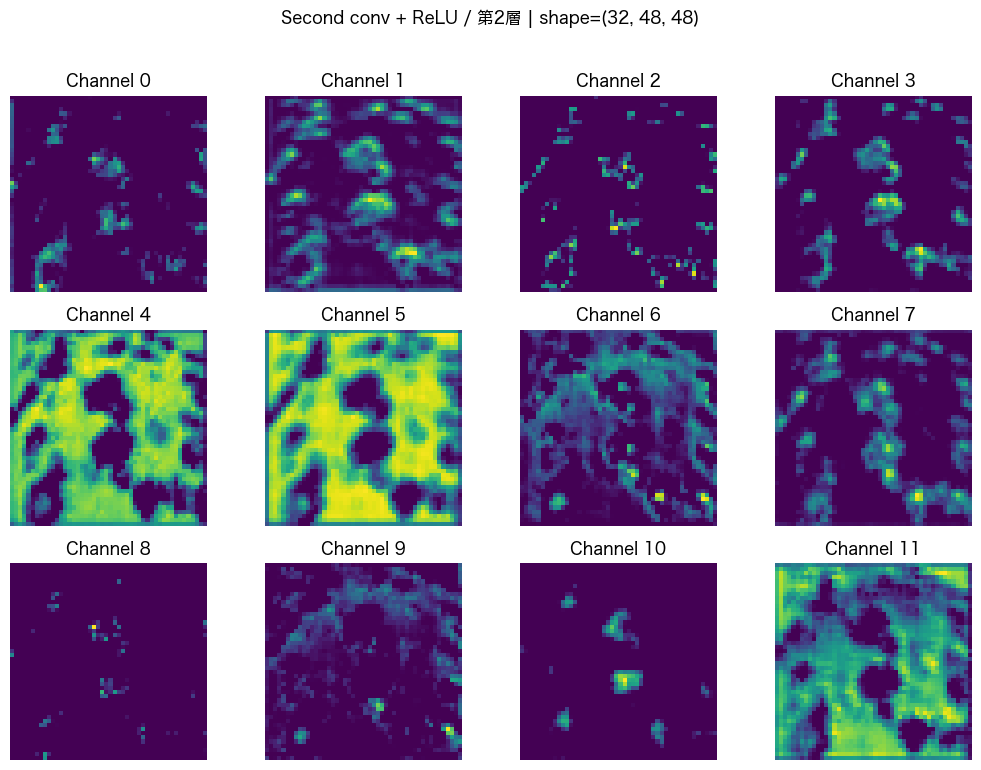

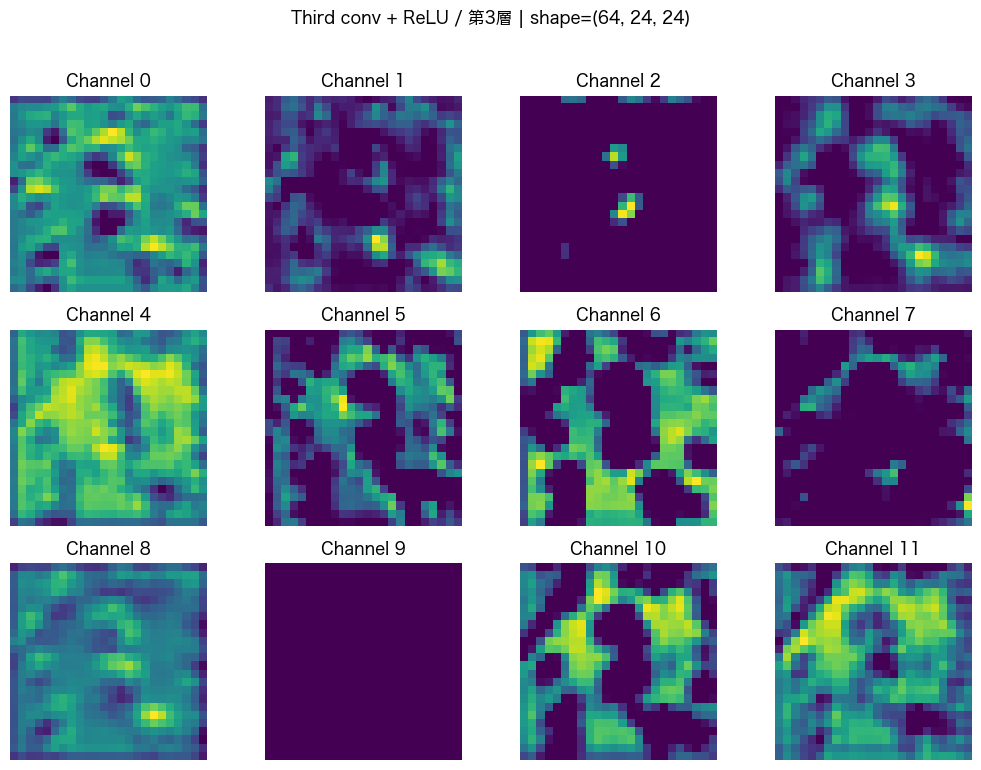

In [19]:
sample_img,sample_y=test_data[1]
plt.figure(figsize=(3,3));plt.imshow(undo_normalize(sample_img));plt.title(f'True: {class_names[sample_y]}');plt.axis('off');plt.show()
map1=show_feature_maps(model,sample_img,model.relu1,'First conv + ReLU / 第1層',max_channels=12)
map2=show_feature_maps(model,sample_img,model.relu2,'Second conv + ReLU / 第2層',max_channels=12)
map3=show_feature_maps(model,sample_img,model.relu3,'Third conv + ReLU / 第3層',max_channels=12)

## 8. Visualize class scores / クラスごとのスコア
**EN:** Softmax turns logits into a distribution across the five labels. The tallest bar indicates the predicted class. A very confident wrong answer is especially valuable to inspect.

**日本語:** Softmaxによって5クラスのスコアを合計1の分布へ変換します。最も高い棒が予測クラスです。確信度が高いのに間違えた画像は、特に重要な分析対象です。

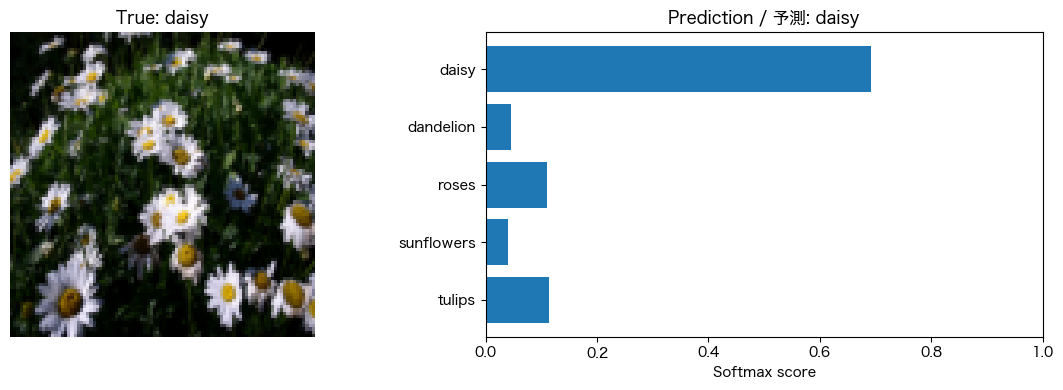

In [20]:
model.eval()
with torch.no_grad():
    p=torch.softmax(model(sample_img.unsqueeze(0).to(DEVICE)),dim=1)[0].cpu().numpy()
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].imshow(undo_normalize(sample_img));axs[0].axis('off');axs[0].set_title(f'True: {class_names[sample_y]}')
axs[1].barh(class_names,p);axs[1].invert_yaxis();axs[1].set_xlim(0,1)
axs[1].set_xlabel('Softmax score');axs[1].set_title(f'Prediction / 予測: {class_names[p.argmax()]}')
plt.tight_layout();plt.show()

## 9. Optional experiment / 追加実験
**EN:** Try changing **one variable at a time**: epochs 3→8, turn off `RandomRotation`, or change `IMAGE_SIZE` from 96→128. Keep the same splits and compare validation loss/accuracy. Changing image size affects speed and memory. When comparing preprocessing choices, build **new** transforms and data loaders, then reconstruct and retrain the model from scratch; otherwise results are not controlled.

**日本語:** **一度に1つだけ**条件を変えましょう：エポック数3→8、`RandomRotation`を無効化、または `IMAGE_SIZE` を96→128に変更します。データ分割を固定し、検証損失・検証正解率を比較してください。サイズ変更は速度・メモリ使用量に影響します。前処理を変えた場合は変換・DataLoaderを作り直し、モデルも新規に初期化して学習してください。

| Setting / 条件 | Validation accuracy / 検証正解率 | Training time / 学習時間 |
|---|---:|---:|
| Baseline: 96px, 3 epochs | *(fill in)* | *(fill in)* |
| More epochs: 96px, 8 epochs | *(fill in)* | *(fill in)* |
| No rotation: 96px, 3 epochs | *(fill in)* | *(fill in)* |

### Compare with MNIST / MNISTとの比較
**EN:** Why is flower classification harder? Consider RGB versus grayscale, complex backgrounds, class similarity, dataset size, and image resolution. Can an early feature map alone identify the flower class?

**日本語:** なぜ花の分類のほうが難しいのでしょうか。RGBとグレースケール、背景の複雑さ、クラス間の類似性、データ数、解像度に着目しましょう。最初の特徴マップだけで花の種類を識別できるでしょうか。

**Further study / 発展:** Transfer learning using pretrained ResNet18 is often a stronger baseline for small real-world datasets. It is deliberately left out of this short lesson. / 実画像が少ない場合は学習済みResNet18などの転移学習が有力ですが、本授業では扱いません。